# Final Analytical Notebook: Executive Decision Report
**Submitted by Rithi Iyswarya M** · Dept. of Artificial Intelligence and Data Science, SKCET

Reproduces every number in the *Executive Decision Report* slide deck. The dataset is **synthetic** (same data as the Streamlit dashboard). Run this notebook next to `data_gen.py` and `roi_model.py`.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import roi_model as rm
from data_gen import kpis, fmt_inr
pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
d = rm.load()
print(d.shape, d.month.min().date(), '→', d.month.max().date())
d.head()

(6000, 14) 2024-01-01 → 2025-12-01


,month,state,region,category,channel,orders,revenue,new_customers,acq_spend,start_customers,churned,lat,lon,year
0,2024-01-01,Tamil Nadu,South,Apparel,Organic,46,"77,059.29",19,0.00,85,6,11.13,78.66,2024
1,2024-01-01,Tamil Nadu,South,Apparel,Paid Search,44,"77,530.24",12,"6,147.12",88,6,11.13,78.66,2024
2,2024-01-01,Tamil Nadu,South,Apparel,Social,44,"85,151.83",14,"5,270.31",93,3,11.13,78.66,2024
3,2024-01-01,Tamil Nadu,South,Apparel,Email,51,"91,494.45",20,"2,295.26",121,8,11.13,78.66,2024
4,2024-01-01,Tamil Nadu,South,Apparel,Referral,40,"70,309.76",13,"2,244.17",75,4,11.13,78.66,2024


## 1. KPI definitions and headline performance
CAC = acquisition spend ÷ new customers · Churn = customers lost ÷ opening customers (monthly) · AOV = revenue ÷ orders.

In [2]:
k = {y: kpis(d[d.year == y]) for y in (2024, 2025)}
t = pd.DataFrame(k).T
t['revenue (₹ Cr)'] = t.revenue / 1e7
t.loc['YoY %'] = (t.loc[2025] / t.loc[2024] - 1) * 100
t[['revenue (₹ Cr)', 'cac', 'churn', 'aov']]

,revenue (₹ Cr),cac,churn,aov
2024,32.80,250.01,5.00,"2,240.97"
2025,41.77,250.01,5.09,"2,236.72"
YoY %,27.34,-0.00,1.64,-0.19


## 2. Revenue drivers: category, geography, channel

In [3]:
def seg(col):
    g = d.groupby(col).agg(rev=('revenue','sum'), orders=('orders','sum'), spend=('acq_spend','sum'),
                           new=('new_customers','sum'), lost=('churned','sum'), opening=('start_customers','sum'))
    g['share %'] = g.rev / g.rev.sum() * 100
    g['AOV'] = g.rev / g.orders
    g['CAC'] = g.spend / g.new
    g['churn %'] = g.lost / g.opening * 100
    return g[['share %', 'AOV', 'CAC', 'churn %']].sort_values('share %', ascending=False)
seg('category')

,share %,AOV,CAC,churn %
category,,,,
Electronics,45.94,"5,196.88",250.41,5.04
Home & Living,23.13,"2,600.74",247.88,5.02
Apparel,16.15,"1,803.47",248.98,5.06
Beauty,8.51,944.07,252.34,5.02
Grocery,6.27,699.41,250.41,5.12


In [4]:
seg('region')

,share %,AOV,CAC,churn %
region,,,,
South,42.27,"2,238.88",248.64,5.08
West,30.38,"2,239.41",251.81,5.07
North,19.53,"2,240.88",250.97,5.02
East,7.83,"2,228.16",248.14,4.90


Top 4 states share: 53.1%
region
East    24.30
North   22.20
South   30.00
West    27.80


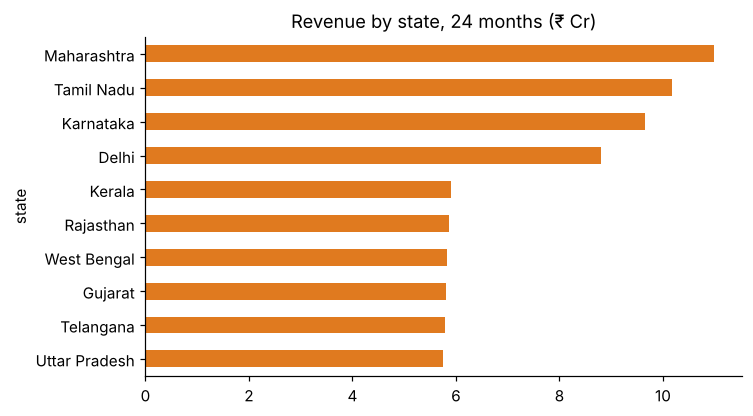

In [5]:
st = d.groupby('state').revenue.sum().sort_values(ascending=False)
print(f'Top 4 states share: {st.head(4).sum() / st.sum() * 100:.1f}%')
p = d.pivot_table(index='region', columns='year', values='revenue', aggfunc='sum')
print((p[2025] / p[2024] - 1).mul(100).round(1).rename('YoY revenue growth %').to_string())
(st / 1e7).sort_values().plot.barh(color='#E07A1F', figsize=(7, 4), title='Revenue by state, 24 months (₹ Cr)')
plt.show()

             rev_share  spend_share    cac
channel                                   
Email            19.80         9.60 120.10
Organic          20.20         0.00   0.00
Paid Search      20.20        41.70 517.00
Referral         19.90        15.90 200.00
Social           19.80        32.80 412.30

Paid Search + Social: 74.5% of acquisition spend, 40.0% of revenue


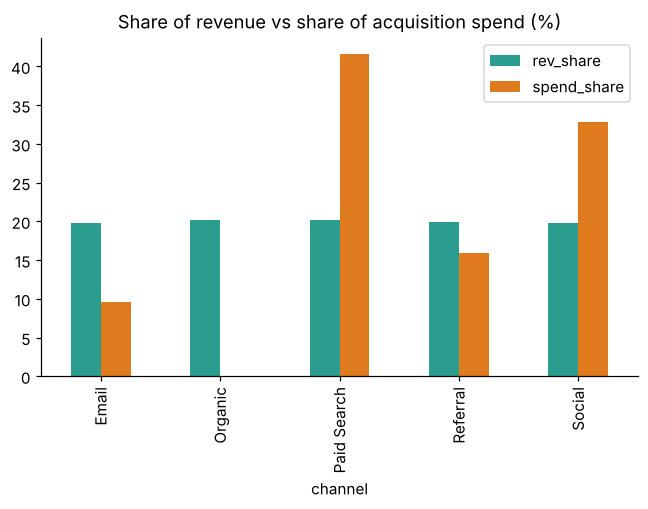

In [6]:
ch = rm.channel_table(d)
print(ch[['rev_share', 'spend_share', 'cac']].round(1).to_string())
F = rm.findings(d)
print(f"\nPaid Search + Social: {F['paid_spend_share']:.1f}% of acquisition spend, {F['paid_rev_share']:.1f}% of revenue")
ch[['rev_share', 'spend_share']].plot.bar(figsize=(7, 4), color=['#2A9D8F', '#E07A1F'], title='Share of revenue vs share of acquisition spend (%)')
plt.show()

## 3. Seasonality

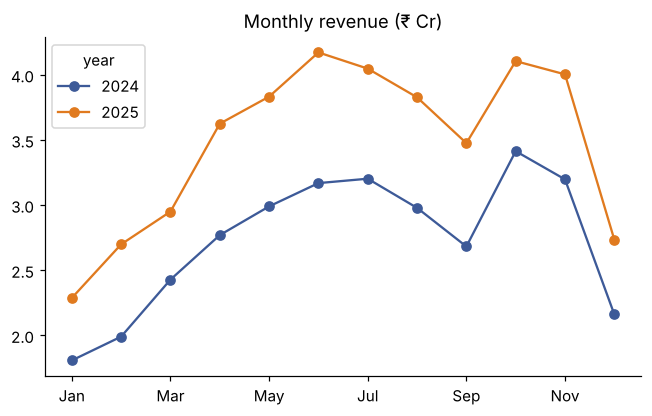

Oct–Dec share of 2025 revenue: 26.0%
Dec vs Nov 2025: -31.7%
Jan–Feb avg vs June 2025: -40.2%


In [7]:
m = d.groupby([d.year, d.month.dt.month]).revenue.sum().unstack(0) / 1e7
m.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
m.plot(marker='o', figsize=(7, 4), color=['#3D5A98', '#E07A1F'], title='Monthly revenue (₹ Cr)')
plt.show()
print(f"Oct–Dec share of 2025 revenue: {F['q4_share']:.1f}%")
print(f"Dec vs Nov 2025: {(m.loc['Dec', 2025] / m.loc['Nov', 2025] - 1) * 100:.1f}%")
print(f"Jan–Feb avg vs June 2025: {((m.loc[['Jan','Feb'], 2025].mean() / m.loc['Jun', 2025]) - 1) * 100:.1f}%")

## 4. Risk areas

Customers lost in 2025: 19,859 of 390,413 opening customer-months


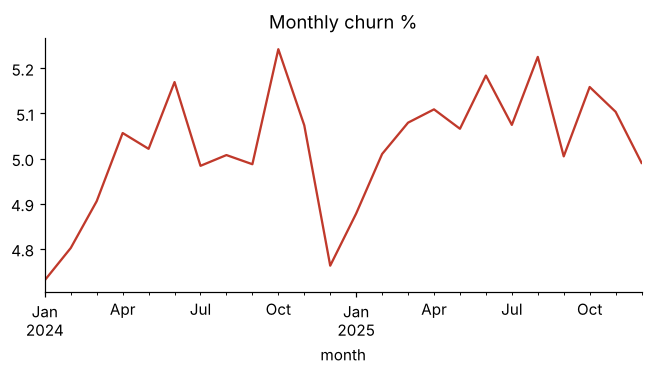

AOV 2024 → 2025: 2241 → 2237


In [8]:
y = d[d.year == 2025]
print(f"Customers lost in 2025: {int(y.churned.sum()):,} of {int(y.start_customers.sum()):,} opening customer-months")
mc = d.groupby('month').apply(lambda x: x.churned.sum() / x.start_customers.sum() * 100, include_groups=False)
mc.plot(figsize=(7, 3), color='#C0392B', title='Monthly churn %'); plt.show()
print(f"AOV 2024 → 2025: {k[2024]['aov']:.0f} → {k[2025]['aov']:.0f}")

## 5. ROI model
Assumptions live in `roi_model.py` (margin, realisation, shift %, churn cut, AOV lift, investment). They are **illustrative**; replace them with company actuals.

In [9]:
R = rm.roi(d)
rows = [{'Recommendation': v['name'], 'Invest (₹ L)': v['invest'] / 1e5, 'Benefit/yr (₹ L)': v['benefit'] / 1e5,
         'ROI %': v['roi'], 'Payback (months)': v['payback_months']} for k_, v in R.items() if k_ in ('realloc', 'retention', 'bundles')]
T = R['total']
rows.append({'Recommendation': 'TOTAL', 'Invest (₹ L)': T['invest'] / 1e5, 'Benefit/yr (₹ L)': T['benefit'] / 1e5,
             'ROI %': T['roi'], 'Payback (months)': T['payback_months']})
pd.DataFrame(rows).set_index('Recommendation')

,Invest (₹ L),Benefit/yr (₹ L),ROI %,Payback (months)
Recommendation,,,,
Reallocate paid acquisition spend,8.00,16.37,104.62,5.86
Retention & win-back programme,20.00,21.93,9.63,10.95
Electronics + Home bundles (AOV),10.00,15.14,51.45,7.92
TOTAL,38.00,53.44,40.63,8.53


In [10]:
print({k_: round(float(v), 1) for k_, v in R['detail'].items()})

{'paid_cac': 465.5, 'cheap_cac': 160.4, 'moved_customers': 7663.5, 'churn_now': 5.1, 'saved_customers': 1952.1, 'rev_per_cust_month': 1069.8, 'big_rev': 288471496.4}


### Sensitivity to the realisation haircut

In [11]:
s = pd.DataFrame({f'{int(r*100)}% realised': {'Total ROI %': rm.roi(d, r)['total']['roi'],
                                                'Payback (months)': rm.roi(d, r)['total']['payback_months']} for r in (0.5, 0.7, 1.0)})
s

,50% realised,70% realised,100% realised
Total ROI %,0.45,40.63,100.91
Payback (months),11.95,8.53,5.97


## 6. Conclusion
1. **Reallocate paid acquisition spend** (Paid Search + Social: ~74% of spend, ~40% of revenue).
2. **Retention and win-back programme** (monthly churn ≈ 5.1%); pilot first, stage gate at Month 7.
3. **Electronics + Home & Living bundles** to lift AOV before the festive peak.

Break-even occurs at roughly half of the modelled benefit; see the sensitivity table above.